# Cooke Triplet

In [1]:
import numpy as np

from optiland import analysis, mtf, optic, psf, wavefront

In [2]:
lens = optic.Optic()

lens.surfaces.add(index=0, radius=np.inf, thickness=np.inf)
lens.surfaces.add(index=1, radius=22.01359, thickness=3.25896, material="SK16")
lens.surfaces.add(index=2, radius=-435.76044, thickness=6.00755)
lens.surfaces.add(
    index=3,
    radius=-22.21328,
    thickness=0.99997,
    material=("F2", "schott"),
)
lens.surfaces.add(index=4, radius=20.29192, thickness=4.75041, is_stop=True)
lens.surfaces.add(index=5, radius=79.68360, thickness=2.95208, material="SK16")
lens.surfaces.add(index=6, radius=-18.39533, thickness=42.20778)
lens.surfaces.add(index=7)

# add aperture
lens.set_aperture(aperture_type="EPD", value=10)

# add field
lens.fields.set_type(field_type="angle")
lens.fields.add(y=0)
lens.fields.add(y=14)
lens.fields.add(y=20)

# add wavelength
lens.wavelengths.add(value=0.48)
lens.wavelengths.add(value=0.55, is_primary=True)
lens.wavelengths.add(value=0.65)

lens.updater.update_paraxial()

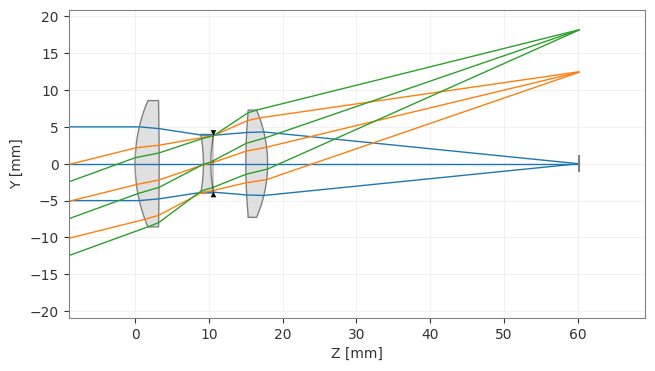

In [3]:
_ = lens.draw()

In [4]:
lens.draw3D()

In [5]:
(
    lens.paraxial.f2(),
    lens.paraxial.F2(),
    lens.paraxial.FNO(),
    lens.paraxial.EPL(),
    lens.paraxial.XPD(),
)

(np.float64(49.999783071431914),
 np.float64(0.2070775589588157),
 np.float64(4.999978307143191),
 np.float64(11.512158673746795),
 np.float64(10.233729452318345))

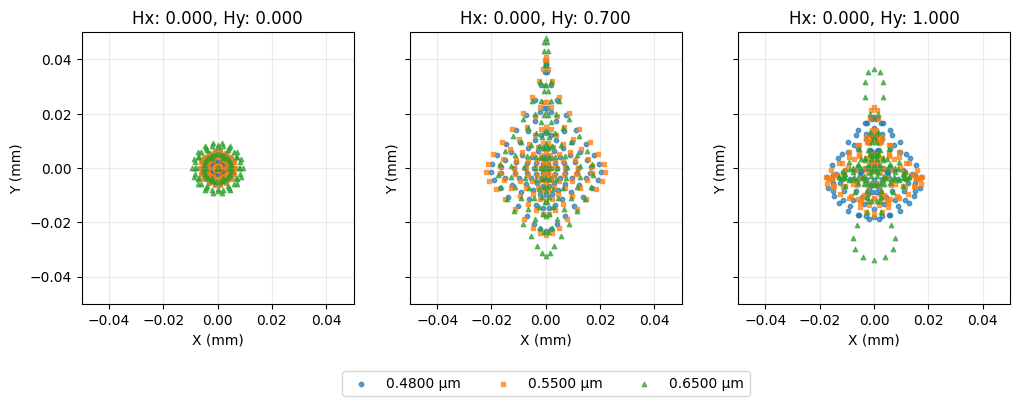

(<Figure size 1200x400 with 3 Axes>,
 [<Axes: title={'center': 'Hx: 0.000, Hy: 0.000'}, xlabel='X (mm)', ylabel='Y (mm)'>,
  <Axes: title={'center': 'Hx: 0.000, Hy: 0.700'}, xlabel='X (mm)', ylabel='Y (mm)'>,
  <Axes: title={'center': 'Hx: 0.000, Hy: 1.000'}, xlabel='X (mm)', ylabel='Y (mm)'>])

In [6]:
spot = analysis.SpotDiagram(lens)
spot.view()

In [7]:
spot.geometric_spot_radius()

[[np.float64(0.00597244087781053),
  np.float64(0.0062864577112478),
  np.float64(0.009319114400642814)],
 [np.float64(0.039284648356172625),
  np.float64(0.040752951556378036),
  np.float64(0.04772194200605284)],
 [np.float64(0.018909146395340456),
  np.float64(0.022501847359631455),
  np.float64(0.036545592330568866)]]

In [8]:
spot.rms_spot_radius()

[[np.float64(0.0037913354614492207),
  np.float64(0.0042936895642583335),
  np.float64(0.0061956187556724465)],
 [np.float64(0.015824800293445462),
  np.float64(0.01691841280970212),
  np.float64(0.019221165873836082)],
 [np.float64(0.013236232767094153),
  np.float64(0.01211668856640782),
  np.float64(0.013648684944411642)]]

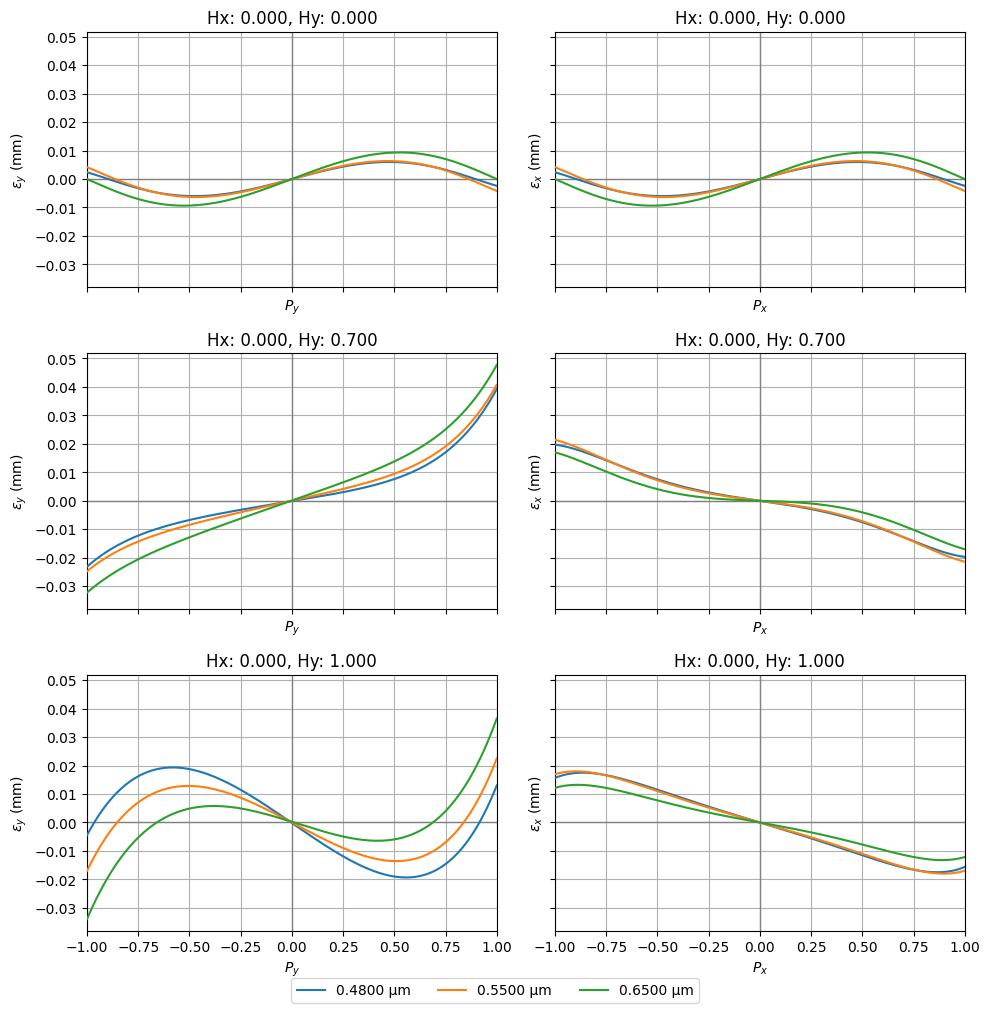

(<Figure size 1000x999 with 6 Axes>,
 [<Axes: title={'center': 'Hx: 0.000, Hy: 0.000'}, xlabel='$P_y$', ylabel='$\\epsilon_y$ (mm)'>,
  <Axes: title={'center': 'Hx: 0.000, Hy: 0.000'}, xlabel='$P_x$', ylabel='$\\epsilon_x$ (mm)'>,
  <Axes: title={'center': 'Hx: 0.000, Hy: 0.700'}, xlabel='$P_y$', ylabel='$\\epsilon_y$ (mm)'>,
  <Axes: title={'center': 'Hx: 0.000, Hy: 0.700'}, xlabel='$P_x$', ylabel='$\\epsilon_x$ (mm)'>,
  <Axes: title={'center': 'Hx: 0.000, Hy: 1.000'}, xlabel='$P_y$', ylabel='$\\epsilon_y$ (mm)'>,
  <Axes: title={'center': 'Hx: 0.000, Hy: 1.000'}, xlabel='$P_x$', ylabel='$\\epsilon_x$ (mm)'>])

In [9]:
fan = analysis.RayFan(lens)
fan.view()

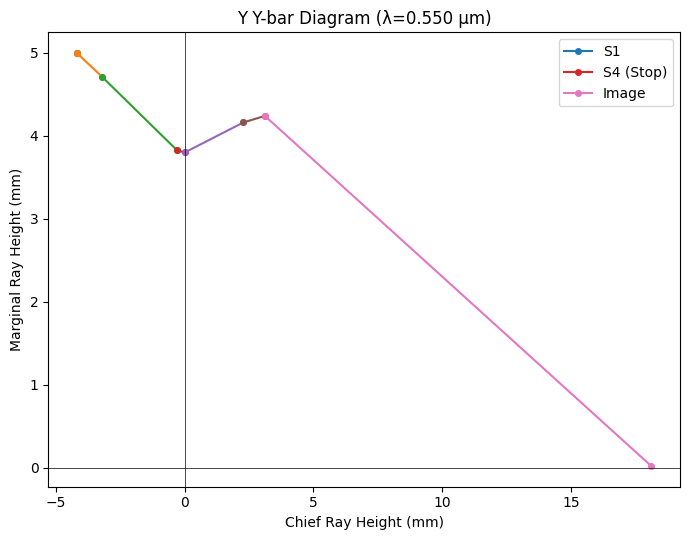

(<Figure size 700x550 with 1 Axes>,
 <Axes: title={'center': 'Y Y-bar Diagram (λ=0.550 µm)'}, xlabel='Chief Ray Height (mm)', ylabel='Marginal Ray Height (mm)'>)

In [10]:
yybar = analysis.YYbar(lens)
yybar.view()

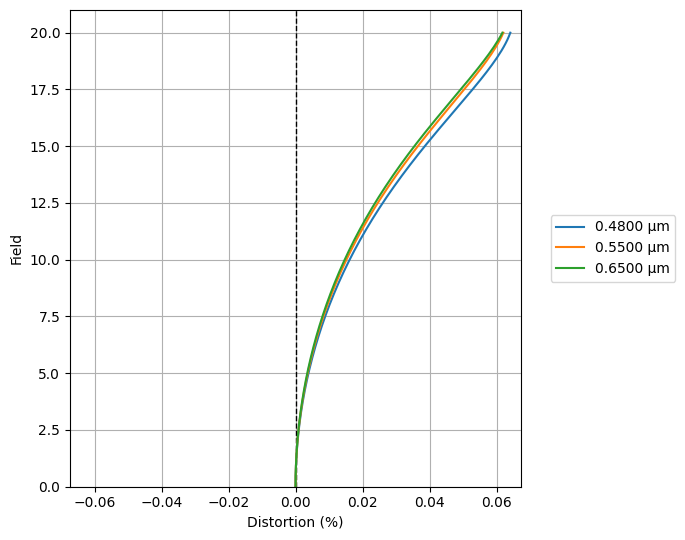

(<Figure size 700x550 with 1 Axes>,
 <Axes: xlabel='Distortion (%)', ylabel='Field'>)

In [11]:
distortion = analysis.Distortion(lens)
distortion.view()

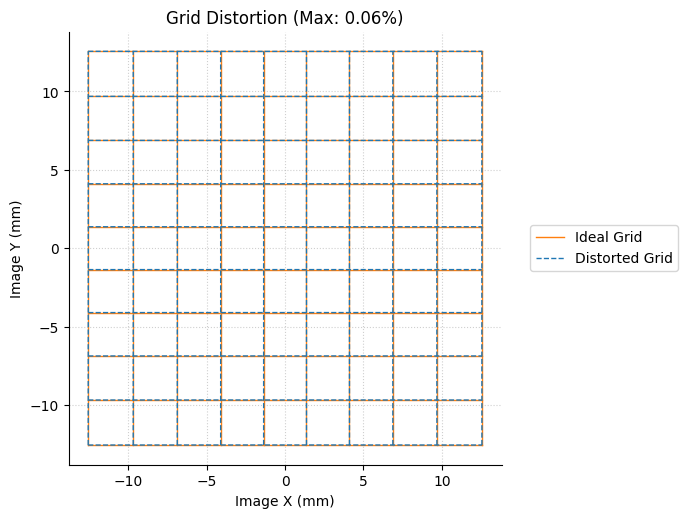

(<Figure size 700x700 with 1 Axes>,
 <Axes: title={'center': 'Grid Distortion (Max: 0.06%)'}, xlabel='Image X (mm)', ylabel='Image Y (mm)'>)

In [12]:
grid = analysis.GridDistortion(lens)
grid.view()

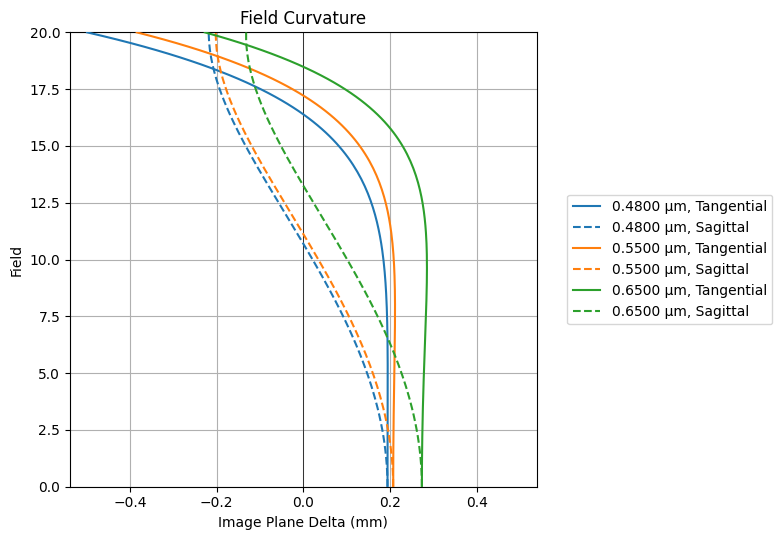

(<Figure size 800x550 with 1 Axes>,
 <Axes: title={'center': 'Field Curvature'}, xlabel='Image Plane Delta (mm)', ylabel='Field'>)

In [13]:
field_curv = analysis.FieldCurvature(lens)
field_curv.view()

(<Figure size 1000x900 with 6 Axes>,
 array([[<Axes: title={'center': 'Hx: 0.000, Hy: 0.000'}, xlabel='$P_y$', ylabel='Wavefront Error (waves)'>,
         <Axes: title={'center': 'Hx: 0.000, Hy: 0.000'}, xlabel='$P_x$', ylabel='Wavefront Error (waves)'>],
        [<Axes: title={'center': 'Hx: 0.000, Hy: 0.700'}, xlabel='$P_y$', ylabel='Wavefront Error (waves)'>,
         <Axes: title={'center': 'Hx: 0.000, Hy: 0.700'}, xlabel='$P_x$', ylabel='Wavefront Error (waves)'>],
        [<Axes: title={'center': 'Hx: 0.000, Hy: 1.000'}, xlabel='$P_y$', ylabel='Wavefront Error (waves)'>,
         <Axes: title={'center': 'Hx: 0.000, Hy: 1.000'}, xlabel='$P_x$', ylabel='Wavefront Error (waves)'>]],
       dtype=object))

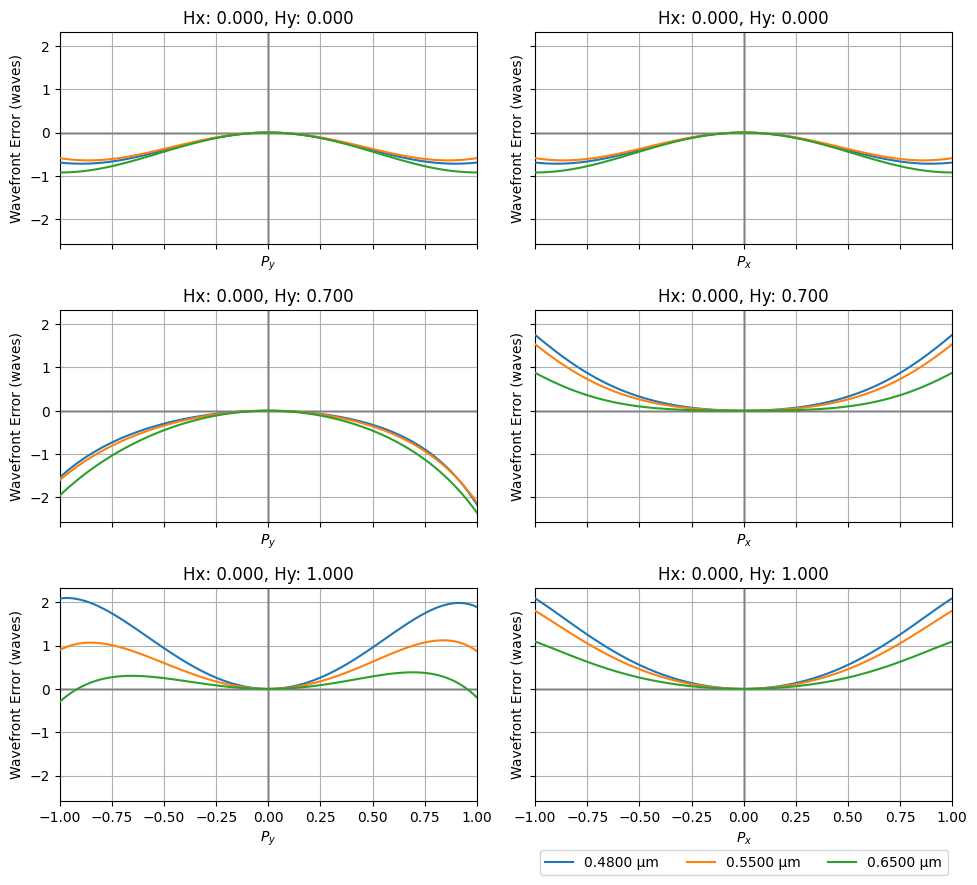

In [14]:
opd_fan = wavefront.OPDFan(lens)
opd_fan.view()

(<Figure size 700x550 with 2 Axes>,
 <Axes: title={'center': 'OPD Map: RMS=0.523 waves'}, xlabel='Pupil X', ylabel='Pupil Y'>)

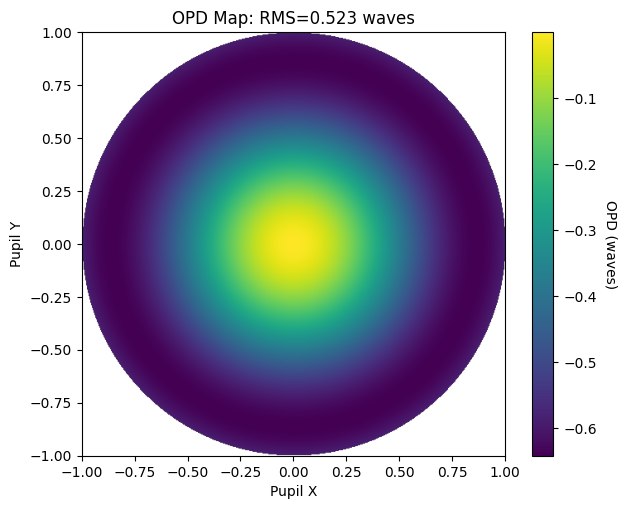

In [15]:
opd = wavefront.OPD(lens, field=(0, 0), wavelength=0.55)
opd.view(projection="2d", num_points=512)

(<Figure size 700x550 with 2 Axes>,
 <Axes: title={'center': 'OPD Map: RMS=0.696 waves'}, xlabel='Pupil X', ylabel='Pupil Y'>)

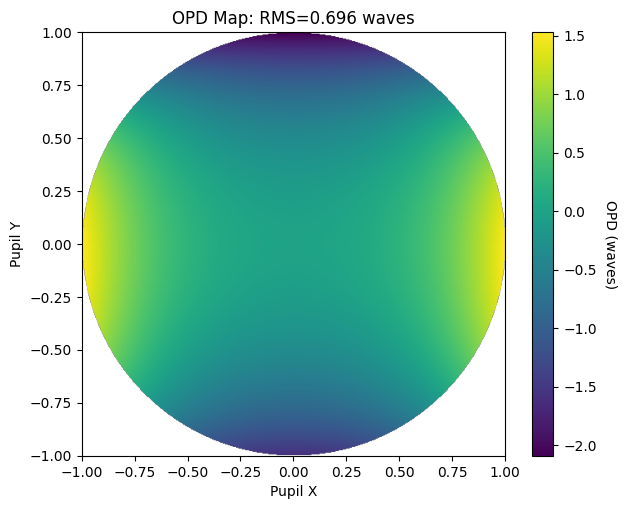

In [16]:
opd = wavefront.OPD(lens, field=(0, 0.7), wavelength=0.55)
opd.view(projection="2d", num_points=512)

(<Figure size 700x550 with 2 Axes>,
 <Axes: title={'center': 'OPD Map: RMS=0.971 waves'}, xlabel='Pupil X', ylabel='Pupil Y'>)

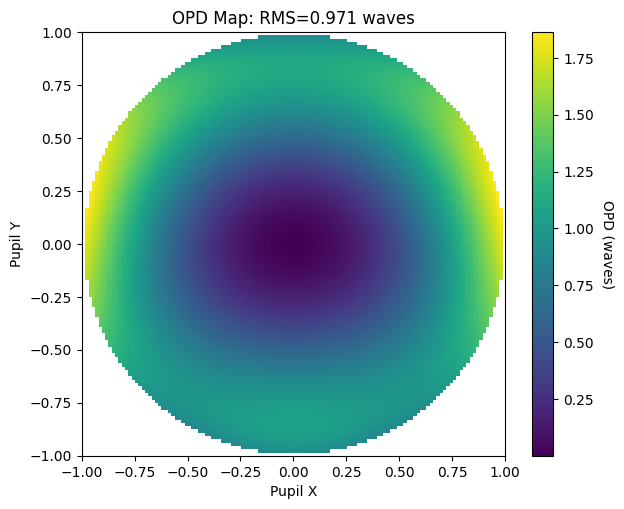

In [17]:
opd = wavefront.OPD(lens, field=(0, 1), wavelength=0.55)
opd.view(projection="2d", num_points=128)

In [18]:
zernike = wavefront.ZernikeOPD(lens, (0, 0), 0.55, zernike_type="fringe")
for k in range(len(zernike.coeffs)):
    print(f"Z{k + 1}: {zernike.coeffs[k]:.8f}")

Z1: -0.48600753
Z2: 0.00000000
Z3: -0.00000000
Z4: -0.27845288
Z5: 0.00000000
Z6: 0.00000000
Z7: 0.00000000
Z8: 0.00000000
Z9: 0.19194955
Z10: -0.00000000
Z11: 0.00000000
Z12: 0.00000000
Z13: 0.00000000
Z14: -0.00000000
Z15: -0.00000000
Z16: -0.01634860
Z17: -0.00000000
Z18: 0.00000000
Z19: 0.00000000
Z20: -0.00000000
Z21: -0.00000000
Z22: 0.00000000
Z23: -0.00000000
Z24: -0.00000000
Z25: -0.00077197
Z26: -0.00000000
Z27: -0.00000000
Z28: 0.00000000
Z29: -0.00000000
Z30: 0.00000000
Z31: -0.00000000
Z32: -0.00000000
Z33: -0.00000000
Z34: -0.00000000
Z35: 0.00000000
Z36: -0.00002947
Z37: -0.00000000


In [19]:
zernike = wavefront.ZernikeOPD(lens, (0, 0), 0.55, zernike_type="noll", num_terms=37)
for k in range(len(zernike.coeffs)):
    print(f"Z{k + 1}: {zernike.coeffs[k]:.8f}")

Z1: -0.48600865
Z2: 0.00000000
Z3: -0.00000000
Z4: -0.16076683
Z5: 0.00000000
Z6: 0.00000000
Z7: 0.00000000
Z8: 0.00000000
Z9: 0.00000000
Z10: -0.00000000
Z11: 0.08584008
Z12: 0.00000000
Z13: 0.00000000
Z14: -0.00000000
Z15: 0.00000000
Z16: -0.00000000
Z17: 0.00000000
Z18: 0.00000000
Z19: -0.00000000
Z20: -0.00000000
Z21: -0.00000000
Z22: -0.00618194
Z23: 0.00000000
Z24: -0.00000000
Z25: -0.00000000
Z26: 0.00000000
Z27: 0.00000000
Z28: 0.00000000
Z29: -0.00000000
Z30: -0.00000000
Z31: -0.00000000
Z32: 0.00000000
Z33: 0.00000000
Z34: 0.00000000
Z35: -0.00000000
Z36: 0.00000000
Z37: -0.00025995


(<Figure size 700x550 with 2 Axes>,
 <Axes: title={'center': 'ScalarFFT PSF'}, xlabel='X (µm)', ylabel='Y (µm)'>)

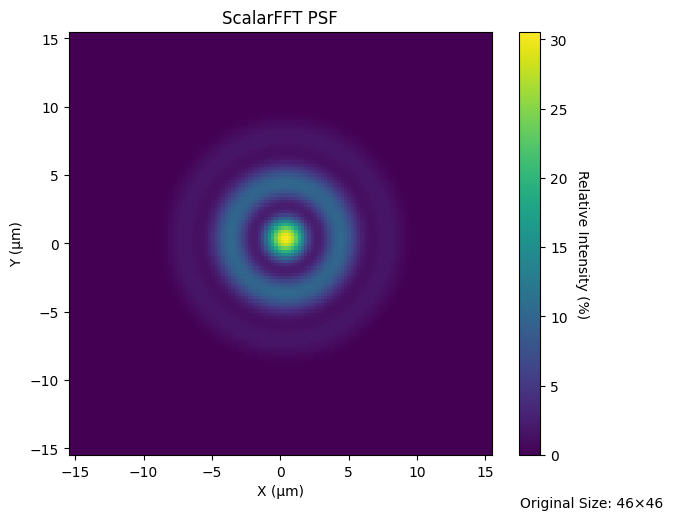

In [20]:
lens_psf = psf.FFTPSF(lens, (0, 0), 0.55)
lens_psf.view(projection="2d", num_points=128)

In [21]:
lens_psf.strehl_ratio()

0.30576757035389873

(<Figure size 700x550 with 2 Axes>,
 <Axes: title={'center': 'ScalarFFT PSF'}, xlabel='X (µm)', ylabel='Y (µm)'>)

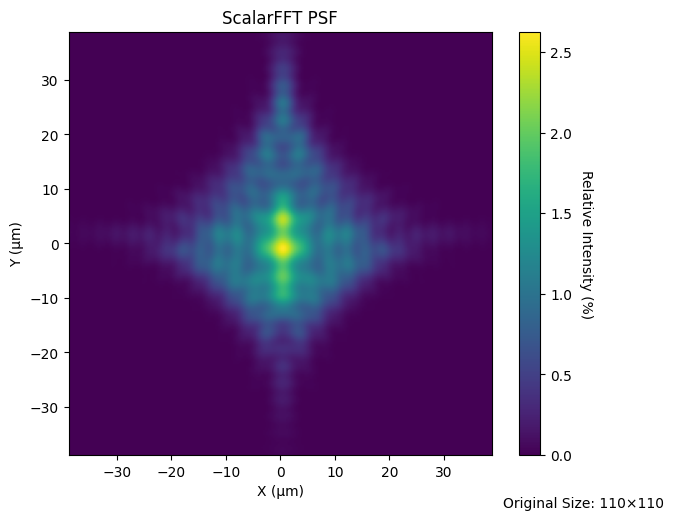

In [22]:
lens_psf = psf.FFTPSF(lens, (0, 0.7), 0.55)
lens_psf.view(num_points=256)

(<Figure size 1200x400 with 1 Axes>,
 <Axes: xlabel='Frequency (cycles/mm)', ylabel='Modulation'>)

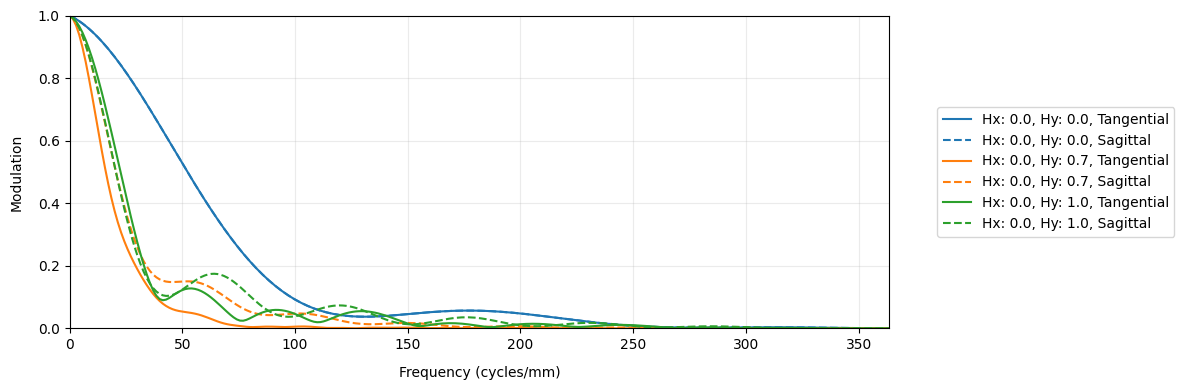

In [23]:
geo_mtf = mtf.GeometricMTF(lens)
geo_mtf.view()

(<Figure size 1200x400 with 1 Axes>,
 <Axes: xlabel='Frequency (cycles/mm)', ylabel='Modulation'>)

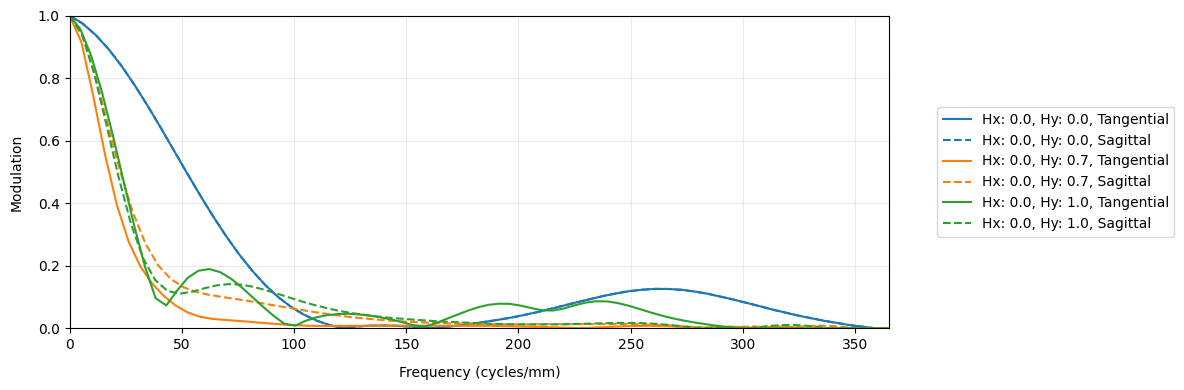

In [24]:
lens_mtf = mtf.FFTMTF(lens)
lens_mtf.view()